# Проверка корректности дизайна A/B-теста

Данные `experiment_data.csv`: группа (`variant`), конверсия (`converted`), guardrail — ошибка загрузки страницы (`error_flag`), активность за неделю до теста (`pre_activity`), дата (`date`).

Истинный дизайн:

- группы 50/50;
- назначение в группу не зависит от `pre_activity`;
- эффекта на конверсию нет.

Проверки на уровне значимости 0.05:

| Проверка | H0 | Предупреждение при p < 0.05 |
| --- | --- | --- |
| SRM | доли групп равны 1/2 | `SRM обнаружен` |
| Баланс `pre_activity` | распределения в группах совпадают | `Дисбаланс по pre_activity — возможен confounder` |
| Guardrail `error_flag` | частоты ошибок равны | `Дисбаланс guardrail-метрики error_flag` |

Хотя бы одно предупреждение — эксперимент не валиден: «Остановить тест, исправить ошибки, перезапустить». Иначе — стандартный анализ конверсии.

## 0. Генерация данных

Seed получен один раз через `np.random.randint(5000000)` и зафиксирован, чтобы файл воспроизводился.

Изменённые параметры рандомизации (нарушения те же, что в шаблоне):

1. `n_users` из диапазона 7000–9500 (внутри разрешённых 1000–10000). На 1–2 тыс. пользователей разница ошибок 1% против 2% часто не значима.
2. Активность нормируется на 95-й перцентиль `pre_activity`, а не на максимум. Максимум экспоненциального распределения — единичный выброс: при делении на него вероятность попасть в test почти одинакова у всех, и confounder не проявляется.
3. `prob_test = 0.25 + 0.55 * score`: средняя доля test не равна 1/2 (SRM) и растёт с активностью (confounder).
4. Ошибки: 1.5% в control, 3.5% в test.
5. Конверсия `0.04 + 0.10 * score` от группы не зависит. В шаблоне наклон 0.01 — смещение от confounder меньше шума.

`date` используется только в дополнительной проверке долей групп по дням (конец ноутбука).

In [1]:
import numpy as np
import pandas as pd

# Seed снят один раз через np.random.randint(5000000) и зафиксирован.
MY_SEED = 2164556
np.random.seed(MY_SEED)

n_users = int(np.random.randint(7000, 9500))

# Ковариата до эксперимента: экспоненциальное число действий за неделю.
pre_activity = np.random.exponential(scale=10, size=n_users).astype(int)

# НАРУШЕНИЕ 1 + НАРУШЕНИЕ 2.
# Доля test не равна 50%, и вероятность назначения растёт вместе с pre_activity.
activity_score = np.clip(pre_activity / np.quantile(pre_activity, 0.95), 0, 1)
prob_test = 0.25 + 0.55 * activity_score
variant = np.where(np.random.random(n_users) < prob_test, "test", "control")

# НАРУШЕНИЕ 3. Guardrail: ошибки загрузки чаще в test, истинного эффекта на конверсию нет.
error_flag = np.zeros(n_users)
error_flag[variant == "control"] = np.random.binomial(1, 0.015, int((variant == "control").sum()))
error_flag[variant == "test"] = np.random.binomial(1, 0.035, int((variant == "test").sum()))

# Конверсия зависит от активности до теста и не зависит от варианта.
conversion_prob = 0.04 + 0.10 * activity_score
converted = np.random.binomial(1, conversion_prob, n_users)

start_date = pd.Timestamp("2026-05-01")
dates = [start_date + pd.Timedelta(days=int(np.random.randint(0, 14))) for _ in range(n_users)]

experiment = pd.DataFrame(
    {
        "user_id": np.arange(n_users),
        "variant": variant,
        "converted": converted.astype(int),
        "error_flag": error_flag.astype(int),
        "pre_activity": pre_activity.astype(int),
        "date": dates,
    }
)
experiment.to_csv("experiment_data.csv", index=False)

print(f"seed = {MY_SEED}")
print(f"пользователей = {n_users}")
print(experiment["variant"].value_counts().to_string())
print("файл: experiment_data.csv")

seed = 2164556
пользователей = 8988
variant
control    5285
test       3703
файл: experiment_data.csv


## 1. Загрузка и описание выборки

Проверка целостности таблицы (пропуски, уникальность `user_id`, допустимые значения) и сводка по группам.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import SplineTransformer

ALPHA = 0.05
CONTROL_COLOR = "#4C78A8"
TEST_COLOR = "#F58518"

plt.rcParams.update(
    {
        "axes.unicode_minus": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "figure.dpi": 110,
    }
)


def format_p(p_value):
    # Обычная запись до 0.0001, дальше научная.
    if p_value < 1e-4:
        return f"{p_value:.2e}"
    return f"{p_value:.4f}"


df = pd.read_csv("experiment_data.csv", parse_dates=["date"])
df["converted"] = df["converted"].astype(int)
df["error_flag"] = df["error_flag"].astype(int)
df["pre_activity"] = df["pre_activity"].astype(int)

problems = []
if df["user_id"].duplicated().any():
    problems.append("user_id не уникален")
if df.isna().any().any():
    problems.append("есть пропуски")
if set(df["variant"].unique()) != {"control", "test"}:
    problems.append("в variant есть значения кроме control и test")
if not set(df["converted"].unique()).issubset({0, 1}):
    problems.append("converted не бинарный")
if not set(df["error_flag"].unique()).issubset({0, 1}):
    problems.append("error_flag не бинарный")

print(f"строк: {len(df):,}".replace(",", " "))
print(f"даты: {df['date'].min().date()} — {df['date'].max().date()} ({df['date'].nunique()} дней)")
if problems:
    print("проблемы качества:", "; ".join(problems))
else:
    print("качество таблицы: пропусков нет, user_id уникален, поля в допустимых значениях")

summary = (
    df.groupby("variant")
    .agg(
        пользователей=("user_id", "size"),
        конверсия=("converted", "mean"),
        частота_ошибок=("error_flag", "mean"),
        pre_activity_среднее=("pre_activity", "mean"),
        pre_activity_медиана=("pre_activity", "median"),
    )
    .reindex(["control", "test"])
)
summary.loc["всего"] = [
    len(df),
    df["converted"].mean(),
    df["error_flag"].mean(),
    df["pre_activity"].mean(),
    df["pre_activity"].median(),
]
display(summary.style.format(
    {
        "пользователей": "{:.0f}",
        "конверсия": "{:.2%}",
        "частота_ошибок": "{:.2%}",
        "pre_activity_среднее": "{:.2f}",
        "pre_activity_медиана": "{:.1f}",
    }
))

строк: 8 988
даты: 2026-05-01 — 2026-05-14 (14 дней)
качество таблицы: пропусков нет, user_id уникален, поля в допустимых значениях


,пользователей,конверсия,частота_ошибок,pre_activity_среднее,pre_activity_медиана
variant,,,,,
control,5285,6.47%,1.42%,7.16,5.0
test,3703,8.10%,3.51%,13.38,10.0
всего,8988,7.14%,2.28%,9.72,7.0


8988 пользователей, 1–14 мая 2026 г.

- control 5285 (58.8%), test 3703 (41.2%);
- `pre_activity`: среднее 7.16 против 13.38, медиана 5 против 10;
- ошибки 1.42% против 3.51%;
- конверсия 6.47% против 8.10%.

Разница конверсий в пользу test (+1.6 п.п.) не интерпретируется до проверок дизайна.

## 2. Sample Ratio Mismatch

Хи-квадрат согласия наблюдаемых размеров групп с ожидаемыми по протоколу (df = 1):

$$\chi^2 = \sum_g \frac{(O_g - E_g)^2}{E_g}, \quad E_g = n/2.$$

control: 5285 (ожидалось 4494)
test:    3703 (ожидалось 4494)
доля test: 41.2% при ожидаемых 50%
chi2 = 278.45, p = 1.63e-62
SRM обнаружен


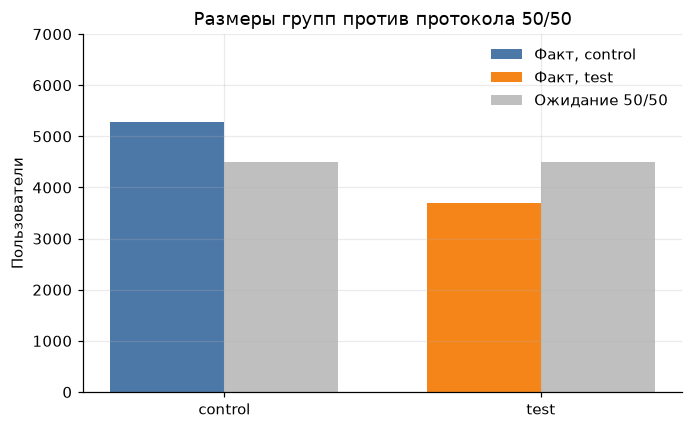

In [3]:
observed_counts = df["variant"].value_counts().reindex(["control", "test"]).astype(int)
expected_counts = np.full(2, len(df) / 2)
chi2_srm, p_srm = stats.chisquare(observed_counts.to_numpy(), f_exp=expected_counts)

srm = {
    "control": int(observed_counts["control"]),
    "test": int(observed_counts["test"]),
    "share_test": observed_counts["test"] / len(df),
    "chi2": float(chi2_srm),
    "p_value": float(p_srm),
}

print(f"control: {srm['control']} (ожидалось {expected_counts[0]:.0f})")
print(f"test:    {srm['test']} (ожидалось {expected_counts[1]:.0f})")
print(f"доля test: {srm['share_test']:.1%} при ожидаемых 50%")
print(f"chi2 = {srm['chi2']:.2f}, p = {format_p(srm['p_value'])}")
if srm["p_value"] < ALPHA:
    print("SRM обнаружен")
else:
    print("SRM не обнаружен: доли согласуются с 50/50")

fig, ax = plt.subplots(figsize=(6.4, 4.0))
x = np.arange(2)
width = 0.36
ax.bar(x - width / 2, observed_counts.to_numpy(), width, color=[CONTROL_COLOR, TEST_COLOR])
ax.bar(x + width / 2, expected_counts, width, color="0.75")
ax.set_xticks(x, ["control", "test"])
ax.set_ylabel("Пользователи")
ax.set_ylim(0, 7000)
ax.set_title("Размеры групп против протокола 50/50")
ax.legend(
    handles=[
        Patch(facecolor=CONTROL_COLOR, label="Факт, control"),
        Patch(facecolor=TEST_COLOR, label="Факт, test"),
        Patch(facecolor="0.75", label="Ожидание 50/50"),
    ],
    frameon=False,
    loc="upper right",
)
fig.tight_layout()
plt.show()

**Вывод.** Доля test 41.2% вместо 50%, $\chi^2 = 278.5$, p ≈ 1.6·10⁻⁶². SRM обнаружен. Возможные причины: вероятность назначения не равна 1/2, потеря событий при логировании, фильтрация после назначения. В любом случае выборка не соответствует протоколу.

## 3. Баланс ковариаты `pre_activity`

Распределение `pre_activity` скошено вправо (целые значения, длинный хвост), нормальность не предполагается. Основной тест — Манна–Уитни (двусторонний), t-тест Уэлча — для сравнения средних. Тест Шапиро–Уилка не используется: на выборке в тысячи наблюдений он отвергает нормальность при любом малом отклонении. Нормальность оценивается по коэффициенту асимметрии и гистограмме.

асимметрия pre_activity: 2.19
среднее  control / test: 7.16 / 13.38
медиана control / test: 5.0 / 10.0
Манн–Уитни: U = 6470312, p = 1.51e-165
Уэлч:       t = -27.50, p = 2.05e-156
Дисбаланс по pre_activity — возможен confounder


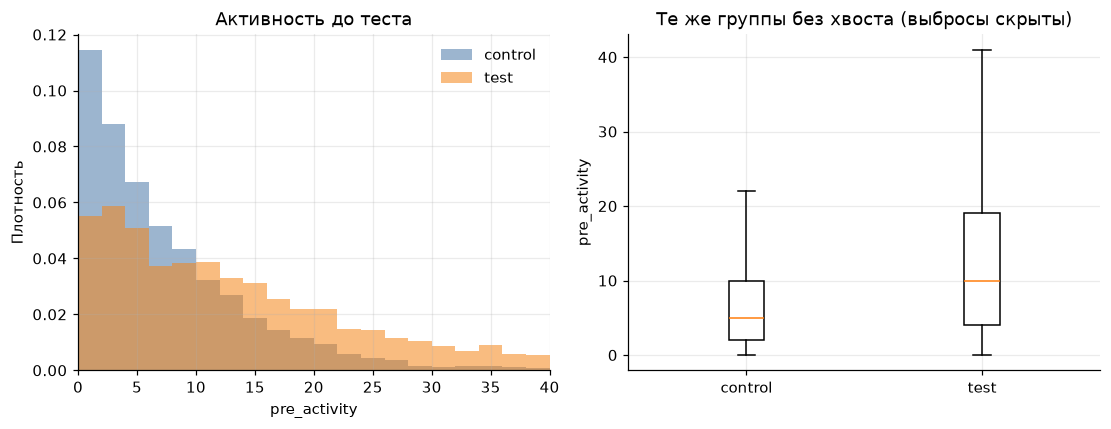

In [4]:
pre_control = df.loc[df["variant"] == "control", "pre_activity"]
pre_test = df.loc[df["variant"] == "test", "pre_activity"]
skewness = float(stats.skew(df["pre_activity"]))

# Основной тест — ранговый: распределение скошено, сравниваем распределения целиком.
u_stat, p_mann = stats.mannwhitneyu(pre_control, pre_test, alternative="two-sided")
# Дополнительно — разница средних. equal_var=False, потому что хвост в test может быть тяжелее.
t_stat, p_welch = stats.ttest_ind(pre_control, pre_test, equal_var=False)

balance = {
    "mean_control": float(pre_control.mean()),
    "mean_test": float(pre_test.mean()),
    "median_control": float(pre_control.median()),
    "median_test": float(pre_test.median()),
    "skewness": skewness,
    "u": float(u_stat),
    "p_mannwhitney": float(p_mann),
    "t": float(t_stat),
    "p_welch": float(p_welch),
}

print(f"асимметрия pre_activity: {skewness:.2f}")
print(
    "среднее  control / test: "
    f"{balance['mean_control']:.2f} / {balance['mean_test']:.2f}"
)
print(
    "медиана control / test: "
    f"{balance['median_control']:.1f} / {balance['median_test']:.1f}"
)
print(f"Манн–Уитни: U = {u_stat:.0f}, p = {format_p(p_mann)}")
print(f"Уэлч:       t = {t_stat:.2f}, p = {format_p(p_welch)}")
if p_mann < ALPHA:
    print("Дисбаланс по pre_activity — возможен confounder")
else:
    print("Дисбаланса по pre_activity нет")

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
bins = np.arange(0, 42, 2)
axes[0].hist(pre_control, bins=bins, density=True, alpha=0.55, color=CONTROL_COLOR, label="control")
axes[0].hist(pre_test, bins=bins, density=True, alpha=0.55, color=TEST_COLOR, label="test")
axes[0].set_xlim(0, 40)
axes[0].set_xlabel("pre_activity")
axes[0].set_ylabel("Плотность")
axes[0].set_title("Активность до теста")
axes[0].legend(frameon=False, loc="upper right")

axes[1].boxplot(
    [pre_control, pre_test],
    tick_labels=["control", "test"],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="white"),
)
axes[1].set_ylabel("pre_activity")
axes[1].set_title("Те же группы без хвоста (выбросы скрыты)")
fig.tight_layout()
plt.show()

**Вывод.** Асимметрия 2.2 — распределение не нормальное. Манна–Уитни: p ≈ 1.5·10⁻¹⁶⁵, Уэлч согласен. Среднее в test выше на 6.2 действия (13.38 против 7.16), медиана 10 против 5. Назначение зависит от активности до теста — confounder. Конверсия растёт с активностью, поэтому сырая разница конверсий смещена в пользу test.

## 4. Guardrail: ошибки загрузки

Частоты `error_flag` по группам и хи-квадрат для таблицы 2×2 без поправки Йетса (ожидаемые частоты — десятки событий; статистика совпадает с квадратом z-теста двух долей).

таблица группа × error_flag:


error_flag,0,1
variant,,
control,5210,75
test,3573,130


частота ошибок control: 1.42% (75 из 5285)
частота ошибок test:    3.51% (130 из 3703)
test / control = 2.47
chi2 = 42.74, df = 1, p = 6.26e-11
z = 6.54, p = 6.26e-11
Дисбаланс guardrail-метрики error_flag


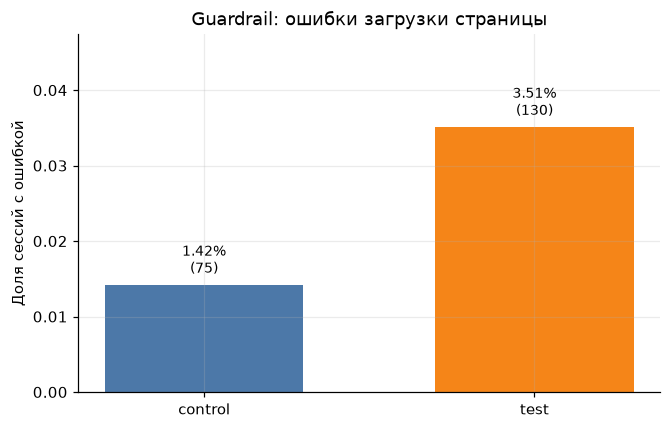

In [5]:
error_table = pd.crosstab(df["variant"], df["error_flag"]).reindex(index=["control", "test"], columns=[0, 1])
chi2_error, p_error, dof_error, expected_error = stats.chi2_contingency(error_table, correction=False)

n_control = int((df["variant"] == "control").sum())
n_test = int((df["variant"] == "test").sum())
errors_control = int(error_table.loc["control", 1])
errors_test = int(error_table.loc["test", 1])
rate_control = errors_control / n_control
rate_test = errors_test / n_test

# z-тест двух долей с объединённой дисперсией — та же H0, что у хи-квадрата.
pooled_error = (errors_control + errors_test) / len(df)
se_error = np.sqrt(pooled_error * (1 - pooled_error) * (1 / n_control + 1 / n_test))
z_error = (rate_test - rate_control) / se_error
p_error_z = float(2 * stats.norm.sf(abs(z_error)))

guard = {
    "rate_control": rate_control,
    "rate_test": rate_test,
    "errors_control": errors_control,
    "errors_test": errors_test,
    "chi2": float(chi2_error),
    "p_value": float(p_error),
    "ratio": rate_test / rate_control,
}

print("таблица группа × error_flag:")
display(error_table)
print(f"частота ошибок control: {rate_control:.2%} ({errors_control} из {n_control})")
print(f"частота ошибок test:    {rate_test:.2%} ({errors_test} из {n_test})")
print(f"test / control = {guard['ratio']:.2f}")
print(f"chi2 = {chi2_error:.2f}, df = {dof_error}, p = {format_p(p_error)}")
print(f"z = {z_error:.2f}, p = {format_p(p_error_z)}")
if p_error < ALPHA:
    print("Дисбаланс guardrail-метрики error_flag")
else:
    print("Guardrail в порядке: частоты ошибок не различаются")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.bar(
    ["control", "test"],
    [rate_control, rate_test],
    color=[CONTROL_COLOR, TEST_COLOR],
    width=0.6,
)
ax.set_ylabel("Доля сессий с ошибкой")
ax.set_title("Guardrail: ошибки загрузки страницы")
ax.set_ylim(0, max(rate_control, rate_test) * 1.35)
for label, rate, count in (("control", rate_control, errors_control), ("test", rate_test, errors_test)):
    ax.text(label, rate + 0.001, f"{rate:.2%}\n({count})", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

**Вывод.** Ошибки 1.42% (75) в control и 3.51% (130) в test — в 2.5 раза чаще, p ≈ 6.3·10⁻¹¹. Guardrail нарушен. Исключать пользователей с ошибкой нельзя: флаг возникает после назначения в группу, отбор по нему смещает сравнение (post-treatment bias).

## 5. Решение о валидности

Решение принимается только по проверкам из разделов 2–4.

In [6]:
warnings = []
if srm["p_value"] < ALPHA:
    warnings.append("SRM обнаружен")
if balance["p_mannwhitney"] < ALPHA:
    warnings.append("Дисбаланс по pre_activity — возможен confounder")
if guard["p_value"] < ALPHA:
    warnings.append("Дисбаланс guardrail-метрики error_flag")

print(f"предупреждений: {len(warnings)}")
for item in warnings:
    print(item)

experiment_valid = len(warnings) == 0
if not experiment_valid:
    print("Остановить тест, исправить ошибки, перезапустить")
else:
    # Ветка стандартного анализа. На этих данных она не выполняется: предупреждения есть.
    conv_table = pd.crosstab(df["variant"], df["converted"]).reindex(index=["control", "test"], columns=[0, 1])
    chi2_conv, p_conv, _, _ = stats.chi2_contingency(conv_table, correction=False)
    rate_c = df.loc[df["variant"] == "control", "converted"].mean()
    rate_t = df.loc[df["variant"] == "test", "converted"].mean()
    print(f"конверсия control = {rate_c:.2%}, test = {rate_t:.2%}")
    print(f"chi2 = {chi2_conv:.2f}, p = {format_p(p_conv)}")
    if p_conv < ALPHA:
        print("Различие конверсий статистически значимо")
    else:
        print("Значимого различия конверсий нет")

предупреждений: 3
SRM обнаружен
Дисбаланс по pre_activity — возможен confounder
Дисбаланс guardrail-метрики error_flag
Остановить тест, исправить ошибки, перезапустить


**Решение.** Сработали все три предупреждения — эксперимент не валиден. **Остановить тест, исправить ошибки, перезапустить.**

Что исправить перед перезапуском:

1. Рандомизатор: P(test) = 1/2 независимо от `pre_activity` и других признаков.
2. Логирование: сверить число назначений с числом строк в аналитической таблице — перекос 59/41 может быть вызван потерей событий.
3. Ошибки загрузки страницы в test.
4. Мониторинг SRM и guardrail ежедневно с первого дня теста.

## 6. Сырая конверсия (иллюстрация)

Расчёт не меняет решение раздела 5: он показывает, какой вывод дал бы анализ без проверки дизайна. z-тест двух долей с объединённой дисперсией под $H_0$, 95% ДИ разницы — с раздельными дисперсиями.

$$SE_{H_0} = \sqrt{\hat p(1-\hat p)\left(\frac{1}{n_c}+\frac{1}{n_t}\right)}.$$

In [7]:
conv_control = df.loc[df["variant"] == "control", "converted"]
conv_test = df.loc[df["variant"] == "test", "converted"]
success_control = int(conv_control.sum())
success_test = int(conv_test.sum())
p_control = success_control / n_control
p_test = success_test / n_test
naive_diff = p_test - p_control

pooled = (success_control + success_test) / len(df)
se_h0 = np.sqrt(pooled * (1 - pooled) * (1 / n_control + 1 / n_test))
z_naive = naive_diff / se_h0
p_naive = float(2 * stats.norm.sf(abs(z_naive)))

se_unpooled = np.sqrt(p_control * (1 - p_control) / n_control + p_test * (1 - p_test) / n_test)
naive_ci = (naive_diff - 1.96 * se_unpooled, naive_diff + 1.96 * se_unpooled)

conv_table = pd.crosstab(df["variant"], df["converted"]).reindex(index=["control", "test"], columns=[0, 1])
chi2_conv, p_chi_conv, _, _ = stats.chi2_contingency(conv_table, correction=False)

naive = {
    "rate_control": p_control,
    "rate_test": p_test,
    "diff": float(naive_diff),
    "ci_low": float(naive_ci[0]),
    "ci_high": float(naive_ci[1]),
    "z": float(z_naive),
    "p_value": p_naive,
}

print(f"конверсия control: {p_control:.2%} ({success_control} из {n_control})")
print(f"конверсия test:    {p_test:.2%} ({success_test} из {n_test})")
print(
    f"разница test − control: {naive_diff:+.2%} "
    f"(95% ДИ [{naive_ci[0]:+.2%}; {naive_ci[1]:+.2%}])"
)
print(f"z = {z_naive:.2f}, p = {format_p(p_naive)}")
print(f"хи-квадрат без поправки Йетса: chi2 = {chi2_conv:.2f}, p = {format_p(p_chi_conv)}")
if p_naive < ALPHA:
    print("Если смотреть только на конверсию, прирост test статистически значим")
else:
    print("Если смотреть только на конверсию, различия нет")

конверсия control: 6.47% (342 из 5285)
конверсия test:    8.10% (300 из 3703)
разница test − control: +1.63% (95% ДИ [+0.53%; +2.73%])
z = 2.95, p = 0.0031
хи-квадрат без поправки Йетса: chi2 = 8.73, p = 0.0031
Если смотреть только на конверсию, прирост test статистически значим


Без учёта дизайна test «выигрывает»: +1.63 п.п. (8.10% против 6.47%), 95% ДИ [+0.53; +2.73] п.п., p = 0.003. Причина — дисбаланс: в test пользователи активнее, а конверсия растёт с активностью. Раздел 7 проверяет это численно.

## 7. Бонус: коррекция дисбаланса `pre_activity`

| Проблема | Исправима на этих данных | Действие |
| --- | --- | --- |
| SRM | Нет | Найти причину, собрать новую выборку |
| Guardrail | Нет | Исправить загрузку; строки с `error_flag = 1` не удалять |
| Confounder `pre_activity` | Частично (оценка чувствительности) | Скорректировать эффект на ковариату |

Три оценки разницы конверсий test − control с учётом `pre_activity`:

1. **Регрессия** (линейная модель вероятности): $\mathrm{converted} = \beta_0 + \beta_1 \mathrm{test} + \beta_2 \mathrm{pre\_activity} + \varepsilon$. $\beta_1$ — разница долей при фиксированной активности. Стандартные ошибки HC1: дисперсия бинарного отклика $p(1-p)$ непостоянна.
2. **Стратификация** по квинтилям `pre_activity`: разница внутри каждой страты, объединение с весами $1/\widehat{\mathrm{Var}}$.
3. **IPW**: propensity score — логистическая регрессия по сплайну $\log(1+\mathrm{pre\_activity})$, стабилизированные веса $P(T=t) / \hat P(T=t \mid X)$, вероятности обрезаны в [0.05, 0.95]. 95% ДИ — перцентильный бутстреп (500 реплик, propensity переоценивается в каждой).

In [8]:
def ols_hc1(y, x):
    # МНК и робастные стандартные ошибки HC1.
    n_obs, n_coef = x.shape
    beta = np.linalg.lstsq(x, y, rcond=None)[0]
    residual = y - x @ beta
    bread = np.linalg.inv(x.T @ x)
    meat = x.T @ (residual[:, None] ** 2 * x)
    covariance = bread @ meat @ bread * (n_obs / (n_obs - n_coef))
    se = np.sqrt(np.diag(covariance))
    return beta, se


is_test = (df["variant"] == "test").to_numpy()
y = df["converted"].to_numpy(dtype=float)
pre = df["pre_activity"].to_numpy(dtype=float)
design = np.column_stack([np.ones(len(df)), is_test.astype(float), pre])
beta, se_beta = ols_hc1(y, design)
z_adj = beta[1] / se_beta[1]
p_adj = float(2 * stats.norm.sf(abs(z_adj)))
adj_ci = (beta[1] - 1.96 * se_beta[1], beta[1] + 1.96 * se_beta[1])

# Разложение: сырой эффект = скорректированный + коэффициент ковариаты × разница средних.
mean_gap = balance["mean_test"] - balance["mean_control"]
omitted_variable_bias = beta[2] * mean_gap

regression = {
    "diff": float(beta[1]),
    "se": float(se_beta[1]),
    "ci_low": float(adj_ci[0]),
    "ci_high": float(adj_ci[1]),
    "p_value": p_adj,
    "pre_coef": float(beta[2]),
    "bias_from_pre": float(omitted_variable_bias),
}

print(f"скорректированная разница: {beta[1]:+.2%}  (95% ДИ [{adj_ci[0]:+.2%}; {adj_ci[1]:+.2%}])")
print(f"z = {z_adj:.2f}, p = {format_p(p_adj)}")
print(f"коэффициент pre_activity: {beta[2]:+.4f} (примерно {beta[2]:+.2%} конверсии на одно действие)")
print(f"вклад дисбаланса активности: {mean_gap:.2f} × {beta[2]:.4f} = {omitted_variable_bias:+.2%}")
print(f"сумма скорректированного эффекта и вклада активности: {beta[1] + omitted_variable_bias:+.2%}")
print(f"сырая разница для сверки: {naive['diff']:+.2%}")

скорректированная разница: -0.26%  (95% ДИ [-1.39%; +0.87%])
z = -0.46, p = 0.6468
коэффициент pre_activity: +0.0030 (примерно +0.30% конверсии на одно действие)
вклад дисбаланса активности: 6.21 × 0.0030 = +1.89%
сумма скорректированного эффекта и вклада активности: +1.63%
сырая разница для сверки: +1.63%


Сырые +1.63 п.п. = −0.26 п.п. (эффект группы при фиксированной активности) + 1.89 п.п. (вклад разницы активности: 6.21 × 0.0030). Скорректированная оценка: 95% ДИ [−1.39; +0.87] п.п., p = 0.65.

,корзина,pre_activity,n_control,n_test,среднее_control,среднее_test,конверсия_control,конверсия_test,разница
0,Q1,"(-0.001, 2.0]",1693,617,0.9,1.0,4.13%,3.73%,-0.41%
1,Q2,"(2.0, 5.0]",1142,564,3.9,4.0,5.17%,5.67%,+0.51%
2,Q3,"(5.0, 9.0]",998,542,7.4,7.5,6.61%,5.17%,-1.45%
3,Q4,"(9.0, 16.0]",901,823,12.5,12.7,9.10%,9.84%,+0.74%
4,Q5,"(16.0, 157.0]",551,1157,24.0,27.8,11.80%,11.75%,-0.04%


объединённая разница: -0.21% (95% ДИ [-1.26%; +0.84%]), p = 0.6971


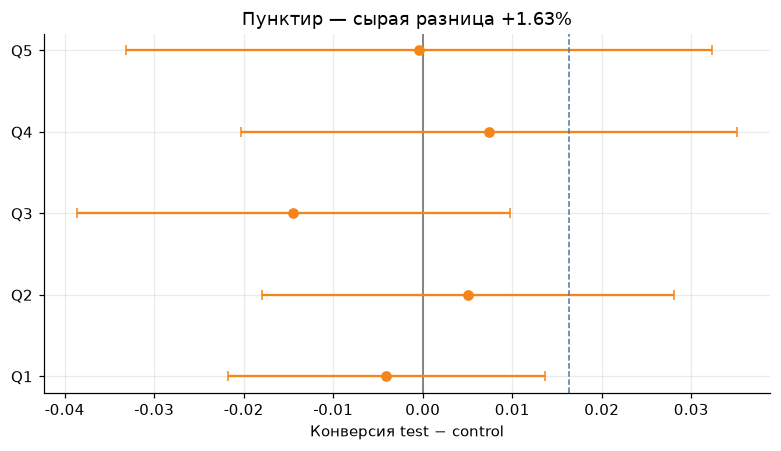

In [9]:
work = df.copy()
work["stratum_bin"] = pd.qcut(work["pre_activity"], 5, duplicates="drop")
stratum_labels = [f"Q{i}" for i in range(1, work["stratum_bin"].nunique() + 1)]
work["stratum"] = work["stratum_bin"].cat.rename_categories(stratum_labels)

stratum_rows = []
for label, group in work.groupby("stratum", observed=True):
    control_part = group[group["variant"] == "control"]
    test_part = group[group["variant"] == "test"]
    rate_c = control_part["converted"].mean()
    rate_t = test_part["converted"].mean()
    diff = rate_t - rate_c
    variance = rate_t * (1 - rate_t) / len(test_part) + rate_c * (1 - rate_c) / len(control_part)
    # Нулевая оценка дисперсии бывает, только если в корзине все исходы одинаковые.
    if variance <= 0:
        variance = 0.25 / len(test_part) + 0.25 / len(control_part)
    stratum_rows.append(
        {
            "корзина": label,
            "pre_activity": str(group["stratum_bin"].iloc[0]),
            "n_control": len(control_part),
            "n_test": len(test_part),
            "среднее_control": control_part["pre_activity"].mean(),
            "среднее_test": test_part["pre_activity"].mean(),
            "конверсия_control": rate_c,
            "конверсия_test": rate_t,
            "разница": diff,
            "дисперсия": variance,
        }
    )

strata = pd.DataFrame(stratum_rows)
weights = 1 / strata["дисперсия"].to_numpy()
strat_diff = float(np.sum(weights * strata["разница"]) / np.sum(weights))
strat_se = float(np.sqrt(1 / np.sum(weights)))
z_strat = strat_diff / strat_se
p_strat = float(2 * stats.norm.sf(abs(z_strat)))
strat_ci = (strat_diff - 1.96 * strat_se, strat_diff + 1.96 * strat_se)

stratified = {
    "diff": strat_diff,
    "se": strat_se,
    "ci_low": float(strat_ci[0]),
    "ci_high": float(strat_ci[1]),
    "p_value": p_strat,
}

display(
    strata.drop(columns="дисперсия").style.format(
        {
            "среднее_control": "{:.1f}",
            "среднее_test": "{:.1f}",
            "конверсия_control": "{:.2%}",
            "конверсия_test": "{:.2%}",
            "разница": "{:+.2%}",
        }
    )
)
print(
    f"объединённая разница: {strat_diff:+.2%} "
    f"(95% ДИ [{strat_ci[0]:+.2%}; {strat_ci[1]:+.2%}]), p = {format_p(p_strat)}"
)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.axvline(0, color="0.4", lw=1)
ax.errorbar(
    strata["разница"],
    np.arange(len(strata)),
    xerr=1.96 * np.sqrt(strata["дисперсия"]),
    fmt="o",
    color=TEST_COLOR,
    capsize=3,
)
ax.axvline(naive["diff"], color=CONTROL_COLOR, ls="--", lw=1)
ax.set_yticks(np.arange(len(strata)), strata["корзина"])
ax.set_xlabel("Конверсия test − control")
ax.set_title(f"Пунктир — сырая разница {naive['diff']:+.2%}")
fig.tight_layout()
plt.show()

Внутри квинтилей разница от −1.45 п.п. (Q3) до +0.74 п.п. (Q4); ни одна страта не воспроизводит +1.63 п.п. Объединённая оценка −0.21 п.п., p = 0.70. В Q5 (16–157 действий) средние всё ещё различаются (24.0 против 27.8): пять страт не выравнивают хвост, регрессия по самой `pre_activity` здесь точнее.

In [10]:
def ipw_risk_difference(pre_values, converted_values, test_mask):
    # Стабилизированный IPW. Возвращает разницу конверсий и веса исходной выборки.
    if test_mask.sum() < 30 or (~test_mask).sum() < 30:
        return np.nan, None
    spline = SplineTransformer(n_knots=6, degree=3, include_bias=False)
    features = spline.fit_transform(np.log1p(pre_values).reshape(-1, 1))
    model = LogisticRegression(C=1e6, solver="lbfgs", max_iter=400)
    model.fit(features, test_mask.astype(int))
    propensity = np.clip(model.predict_proba(features)[:, 1], 0.05, 0.95)
    share_test = float(test_mask.mean())
    weights = np.where(test_mask, share_test / propensity, (1 - share_test) / (1 - propensity))
    rate_test = np.average(converted_values[test_mask], weights=weights[test_mask])
    rate_control = np.average(converted_values[~test_mask], weights=weights[~test_mask])
    return float(rate_test - rate_control), weights


ipw_diff, ipw_weights = ipw_risk_difference(pre, y, is_test)
weighted_pre_control = np.average(pre[~is_test], weights=ipw_weights[~is_test])
weighted_pre_test = np.average(pre[is_test], weights=ipw_weights[is_test])
effective_n = float((ipw_weights.sum() ** 2) / np.sum(ipw_weights ** 2))

rng = np.random.default_rng(0)
n_bootstrap = 500
bootstrap_diffs = np.empty(n_bootstrap)
for draw in range(n_bootstrap):
    sample_index = rng.integers(0, len(df), len(df))
    bootstrap_diffs[draw], _ = ipw_risk_difference(pre[sample_index], y[sample_index], is_test[sample_index])

ipw_ci_low, ipw_ci_high = np.nanquantile(bootstrap_diffs, [0.025, 0.975])
# Двусторонняя бутстреп-оценка: доля реплик по другую сторону от нуля, умноженная на 2.
bootstrap_p = float(2 * min(np.mean(bootstrap_diffs <= 0), np.mean(bootstrap_diffs >= 0)))

ipw = {
    "diff": ipw_diff,
    "ci_low": float(ipw_ci_low),
    "ci_high": float(ipw_ci_high),
    "p_value": bootstrap_p,
    "pre_control": float(weighted_pre_control),
    "pre_test": float(weighted_pre_test),
    "effective_n": effective_n,
    "weight_min": float(ipw_weights.min()),
    "weight_max": float(ipw_weights.max()),
}

print(
    f"IPW-разница: {ipw_diff:+.2%} "
    f"(95% ДИ [{ipw_ci_low:+.2%}; {ipw_ci_high:+.2%}]), бутстреп p ≈ {format_p(bootstrap_p)}"
)
print(
    "среднее pre_activity после взвешивания, control / test: "
    f"{weighted_pre_control:.2f} / {weighted_pre_test:.2f}"
)
print(
    f"эффективный размер выборки: {effective_n:.0f} из {len(df)}, "
    f"веса от {ipw_weights.min():.2f} до {ipw_weights.max():.2f}"
)

IPW-разница: -0.37% (95% ДИ [-1.46%; +0.80%]), бутстреп p ≈ 0.5560
среднее pre_activity после взвешивания, control / test: 9.75 / 9.73
эффективный размер выборки: 7980 из 8988, веса от 0.49 до 3.68


После взвешивания средняя `pre_activity` ≈ 9.7 в обеих группах (было 7.16 и 13.38). Веса 0.49–3.68, эффективный размер выборки ≈ 7980 из 8988 — оценка не держится на отдельных наблюдениях. Эффект −0.37 п.п., 95% ДИ содержит ноль.

,оценка,эффект,ди_низ,ди_верх,p_value
0,Сырая разница,+1.63%,+0.53%,+2.73%,0.0031
1,"Регрессия, HC1",-0.26%,-1.39%,+0.87%,0.6468
2,Квантили pre_activity,-0.21%,-1.26%,+0.84%,0.6971
3,IPW по сплайну,-0.37%,-1.46%,+0.80%,0.5560


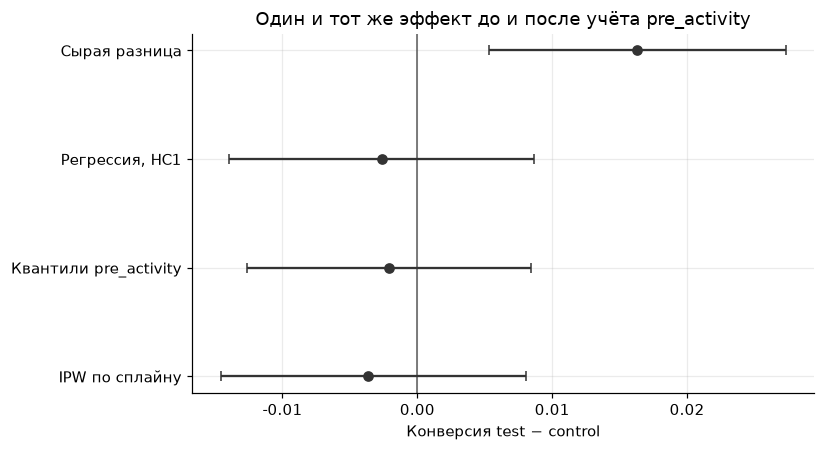

Вывод после исправления дисбаланса: значимый прирост test объясняется разным составом групп по pre_activity. Скорректированные оценки с нулём согласуются.
На решение по эксперименту это не влияет: SRM и guardrail остаются, тест нужно остановить и перезапустить.


In [11]:
comparison = pd.DataFrame(
    [
        {
            "оценка": "Сырая разница",
            "эффект": naive["diff"],
            "ди_низ": naive["ci_low"],
            "ди_верх": naive["ci_high"],
            "p_value": naive["p_value"],
        },
        {
            "оценка": "Регрессия, HC1",
            "эффект": regression["diff"],
            "ди_низ": regression["ci_low"],
            "ди_верх": regression["ci_high"],
            "p_value": regression["p_value"],
        },
        {
            "оценка": "Квантили pre_activity",
            "эффект": stratified["diff"],
            "ди_низ": stratified["ci_low"],
            "ди_верх": stratified["ci_high"],
            "p_value": stratified["p_value"],
        },
        {
            "оценка": "IPW по сплайну",
            "эффект": ipw["diff"],
            "ди_низ": ipw["ci_low"],
            "ди_верх": ipw["ci_high"],
            "p_value": ipw["p_value"],
        },
    ]
)

display(
    comparison.style.format(
        {
            "эффект": "{:+.2%}",
            "ди_низ": "{:+.2%}",
            "ди_верх": "{:+.2%}",
            "p_value": lambda value: format_p(value),
        }
    )
)

fig, ax = plt.subplots(figsize=(7.6, 4.2))
y_pos = np.arange(len(comparison))[::-1]
ax.axvline(0, color="0.35", lw=1)
ax.errorbar(
    comparison["эффект"],
    y_pos,
    xerr=[
        comparison["эффект"] - comparison["ди_низ"],
        comparison["ди_верх"] - comparison["эффект"],
    ],
    fmt="o",
    color="#333333",
    capsize=3,
)
ax.set_yticks(y_pos, comparison["оценка"])
ax.set_xlabel("Конверсия test − control")
ax.set_title("Один и тот же эффект до и после учёта pre_activity")
fig.tight_layout()
plt.show()

raw_is_significant = naive["p_value"] < ALPHA
adjusted_are_quiet = (
    regression["p_value"] >= ALPHA
    and stratified["p_value"] >= ALPHA
    and ipw["ci_low"] <= 0 <= ipw["ci_high"]
)
if raw_is_significant and adjusted_are_quiet:
    print(
        "Вывод после исправления дисбаланса: значимый прирост test объясняется "
        "разным составом групп по pre_activity. Скорректированные оценки с нулём согласуются."
    )
elif raw_is_significant:
    print("Сырой эффект значим, и корректировка это значимое различие не снимает.")
else:
    print("Сырой эффект и так незначим; корректировка меняет точечную оценку, но не статус вывода.")
print(
    "На решение по эксперименту это не влияет: SRM и guardrail остаются, "
    "тест нужно остановить и перезапустить."
)

### Дополнительно: доли групп по дням

Хи-квадрат для таблицы дата × группа: сосредоточен ли перекос долей в отдельных днях.

chi2 = 7.92, df = 13, p = 0.8485
доля test по дням: от 39.1% до 43.9%
Связи группы с датой нет: перекос долей одинаков во все 14 дней


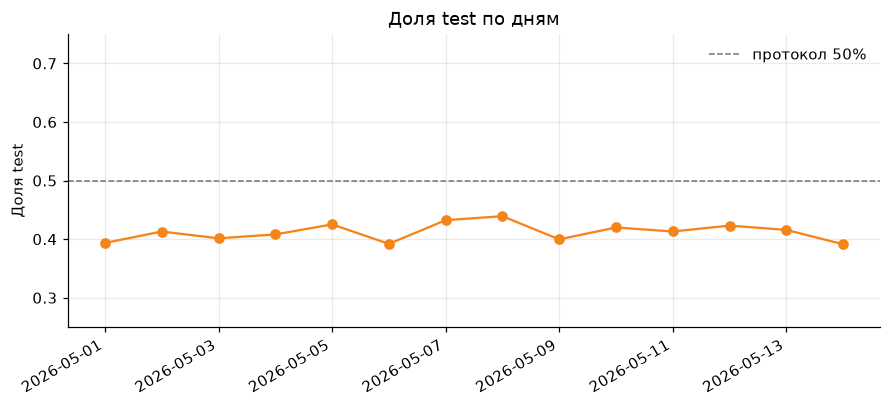

In [12]:
date_table = pd.crosstab(df["date"], df["variant"]).reindex(columns=["control", "test"])
chi2_date, p_date, dof_date, _ = stats.chi2_contingency(date_table, correction=False)
daily_share = date_table["test"] / date_table.sum(axis=1)

print(f"chi2 = {chi2_date:.2f}, df = {dof_date}, p = {format_p(p_date)}")
print(f"доля test по дням: от {daily_share.min():.1%} до {daily_share.max():.1%}")
if p_date < ALPHA:
    print("Доли групп зависят от даты — к списку проблем добавляется временной перекос")
else:
    print("Связи группы с датой нет: перекос долей одинаков во все 14 дней")

fig, ax = plt.subplots(figsize=(8.2, 3.8))
ax.axhline(0.5, color="0.45", ls="--", lw=1, label="протокол 50%")
ax.plot(daily_share.index, daily_share.to_numpy(), marker="o", color=TEST_COLOR)
ax.set_ylim(0.25, 0.75)
ax.set_ylabel("Доля test")
ax.set_title("Доля test по дням")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Итог

Эксперимент не валиден (seed 2164556, 8988 пользователей):

1. **SRM**: доля test 41.2% вместо 50%, p ≪ 0.05; перекос одинаков во все 14 дней.
2. **Confounder**: `pre_activity` в test выше (среднее 13.38 против 7.16), Манна–Уитни p ≪ 0.05.
3. **Guardrail**: ошибки 3.51% против 1.42%, p ≪ 0.05.

**Остановить тест, исправить ошибки, перезапустить.**

Сырая разница конверсий +1.63 п.п. (p = 0.003) — ложный эффект. После учёта `pre_activity`: регрессия −0.26 п.п., стратификация −0.21 п.п., IPW −0.37 п.п.; все 95% ДИ содержат ноль. Коррекция объясняет ложный эффект, но не делает эксперимент валидным: SRM и рост ошибок ею не устраняются.

Для перезапуска: P(test) = 1/2 без зависимости от `pre_activity`, ежедневный мониторинг SRM, исправленная загрузка страницы. `pre_activity` в новом тесте — ковариата для CUPED или регрессии.